# Actual-Optimality Gap

Checks how far the surrogate-optimal allocation is from the actual-error optimum on a small compact sample.


In [1]:
from pathlib import Path
import importlib
import sys

from IPython.display import Markdown, display
import matplotlib.pyplot as plt

# Resolve paths whether the notebook is launched from the repository root or this folder.
working_directory = Path.cwd().resolve()
PROJECT_DIRECTORY = (
    working_directory / "min-error-sequential"
    if (working_directory / "min-error-sequential").is_dir()
    else working_directory
)
SOURCE_DIRECTORY = PROJECT_DIRECTORY / "src"
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))

import actual_optimal_analysis
actual_optimal_analysis = importlib.reload(actual_optimal_analysis)

print("Project directory:", PROJECT_DIRECTORY)
print("Source directory:", SOURCE_DIRECTORY)


Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential
Source directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/src


## Settings

`RUN_SCOPE = "test"` keeps the quick validation sample: compact test results, `K={3,4}`, `M={3,4}`, and one replicate per cell.

`RUN_SCOPE = "full"` is the larger validation sample: compact full results, `K={3,4}`, `M={3,4}`, and three replicates per cell. The actual-optimal search is still intentionally restricted to small `K` and `M` because it enumerates allocations and adaptive trees under actual Helstrom branch probabilities.


In [2]:
DATASETS = ("compact_benchmark_1d", "compact_benchmark_2d")
RUN_SCOPE = "full"  # Use "full" for the larger validation sample.

SCOPE_SETTINGS = {
    "test": {
        "comparison_run_scope": "test",
        "replicates_per_cell": 1,
        "k_values": (3, 4),
        "m_values": (3, 4),
    },
    "full": {
        "comparison_run_scope": "full",
        "replicates_per_cell": 3,
        "k_values": (3, 4),
        "m_values": (3, 4),
    },
}
if RUN_SCOPE not in SCOPE_SETTINGS:
    raise ValueError(f"RUN_SCOPE must be one of {sorted(SCOPE_SETTINGS)}")

scope_settings = SCOPE_SETTINGS[RUN_SCOPE]
COMPARISON_RUN_SCOPE = scope_settings["comparison_run_scope"]
REPLICATES_PER_CELL = scope_settings["replicates_per_cell"]
K_VALUES = scope_settings["k_values"]
M_VALUES = scope_settings["m_values"]
SAMPLE_SCOPE = actual_optimal_analysis.sample_scope_name(
    REPLICATES_PER_CELL,
    comparison_run_scope=COMPARISON_RUN_SCOPE,
    k_values=K_VALUES,
    m_values=M_VALUES,
)

RUN_ACTUAL_OPTIMAL_SEARCH = True
SAVE_FIGURES = True

COMPARISON_RESULTS_ROOT = PROJECT_DIRECTORY / "results" / "cmp_compact"
RESULTS_ROOT = PROJECT_DIRECTORY / "results" / "actual_optimal"
INPUT_ROOT = PROJECT_DIRECTORY / "inputs"

print("Datasets:", DATASETS)
print("Run scope:", RUN_SCOPE)
print("Comparison run scope:", COMPARISON_RUN_SCOPE)
print("Replicates per cell:", REPLICATES_PER_CELL)
print("K values:", K_VALUES)
print("M values:", M_VALUES)
print("Sample scope:", SAMPLE_SCOPE)
print("Run actual-optimal search:", RUN_ACTUAL_OPTIMAL_SEARCH)


Datasets: ('compact_benchmark_1d', 'compact_benchmark_2d')
Run scope: full
Comparison run scope: full
Replicates per cell: 3
K values: (3, 4)
M values: (3, 4)
Sample scope: full_k3-4_m3-4_replicate_3
Run actual-optimal search: True


Starting compact_benchmark_1d
compact_benchmark_1d: selected 143 records (36 cases, K=[3, 4], M=[3, 4])
compact_benchmark_1d: evaluated 1/143 (case=case_00001, field=gaussian, K=3, M=3, budget_level=1, N=2)
compact_benchmark_1d: evaluated 2/143 (case=case_00001, field=gaussian, K=3, M=3, budget_level=2, N=4)
compact_benchmark_1d: evaluated 3/143 (case=case_00001, field=gaussian, K=3, M=3, budget_level=3, N=6)
compact_benchmark_1d: evaluated 4/143 (case=case_00001, field=gaussian, K=3, M=3, budget_level=4, N=7)
compact_benchmark_1d: evaluated 5/143 (case=case_00002, field=gaussian, K=3, M=3, budget_level=1, N=2)
compact_benchmark_1d: evaluated 6/143 (case=case_00002, field=gaussian, K=3, M=3, budget_level=2, N=4)
compact_benchmark_1d: evaluated 7/143 (case=case_00002, field=gaussian, K=3, M=3, budget_level=3, N=6)
compact_benchmark_1d: evaluated 8/143 (case=case_00002, field=gaussian, K=3, M=3, budget_level=4, N=8)
compact_benchmark_1d: evaluated 9/143 (case=case_00003, field=gaussian, 

## 1D Compact Sample

### Overall Actual-Optimality Gap

| Dataset | Dimension | Runs | Mean P_actual(surrogate-optimal) | Mean P_actual(actual-optimal) | Mean gap | Max gap | Mean search seconds | Allocation match | Mean allocation L1 |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| compact_benchmark_1d | 1D | 143 | 0.147170 | 0.144581 | 0.002590 | 0.032813 | 18.020 | 90.2% | 0.60 |

### Actual-Optimality Gap by Field Family

| Dataset | Dimension | Field family | Runs | Mean P_actual(surrogate-optimal) | Mean P_actual(actual-optimal) | Mean gap | Max gap | Mean search seconds | Allocation match | Mean allocation L1 |
|---|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| compact_benchmark_1d | 1D | gaussian | 48 | 0.132000 | 0.129256 | 0.002743 | 0.029796 | 13.279 | 91.7% | 0.25 |
| compact_benchmark_1d | 1D | sinusoidal | 47 | 0.107579 | 0.105348 | 0.002231 | 0.032813 | 11.953 | 85.1% | 1.11 |
| compact_benchmark_1d | 1D | quadratic | 48 | 0.201108 | 0.198320 | 0.002788 | 0.022495 | 28.704 | 93.8% | 0.46 |

### Actual-Optimality Gap by Budget

| Dataset | Dimension | Budget level | Budget ratio | Runs | P_actual(surrogate-optimal) | P_actual(actual-optimal) | Gap | Allocation match | Mean allocation L1 |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| compact_benchmark_1d | 1D | 1 | 0.213 | 36 | 0.323029 | 0.319756 | 0.003273 | 91.7% | 0.33 |
| compact_benchmark_1d | 1D | 2 | 0.399 | 36 | 0.159525 | 0.154824 | 0.004701 | 80.6% | 1.00 |
| compact_benchmark_1d | 1D | 3 | 0.601 | 36 | 0.068925 | 0.067194 | 0.001731 | 94.4% | 0.39 |
| compact_benchmark_1d | 1D | 4 | 0.762 | 35 | 0.034061 | 0.033461 | 0.000600 | 94.3% | 0.69 |

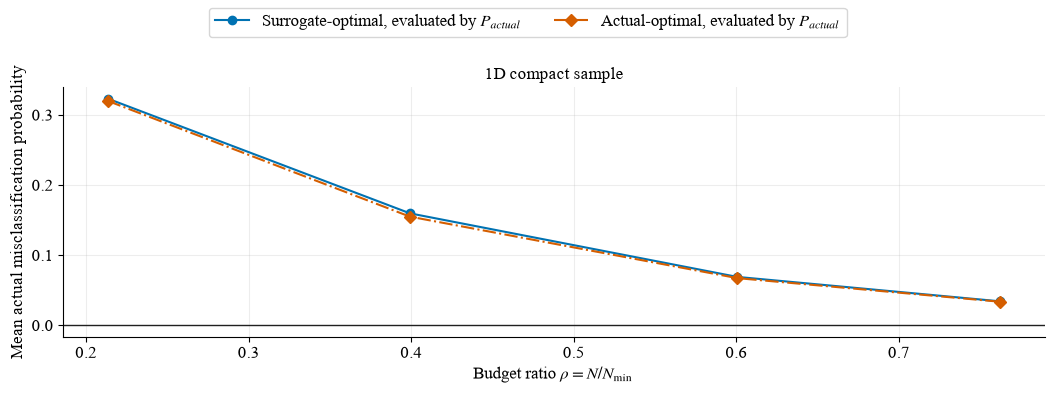

Finished compact_benchmark_1d
Starting compact_benchmark_2d
compact_benchmark_2d: selected 143 records (36 cases, K=[3, 4], M=[3, 4])
compact_benchmark_2d: evaluated 1/143 (case=case_00001, field=gaussian, K=3, M=3, budget_level=1, N=3)
compact_benchmark_2d: evaluated 2/143 (case=case_00001, field=gaussian, K=3, M=3, budget_level=2, N=5)
compact_benchmark_2d: evaluated 3/143 (case=case_00001, field=gaussian, K=3, M=3, budget_level=3, N=7)
compact_benchmark_2d: evaluated 4/143 (case=case_00001, field=gaussian, K=3, M=3, budget_level=4, N=9)
compact_benchmark_2d: evaluated 5/143 (case=case_00002, field=gaussian, K=3, M=3, budget_level=1, N=3)
compact_benchmark_2d: evaluated 6/143 (case=case_00002, field=gaussian, K=3, M=3, budget_level=2, N=6)
compact_benchmark_2d: evaluated 7/143 (case=case_00002, field=gaussian, K=3, M=3, budget_level=3, N=9)
compact_benchmark_2d: evaluated 8/143 (case=case_00002, field=gaussian, K=3, M=3, budget_level=4, N=12)
compact_benchmark_2d: evaluated 9/143 (ca

## 2D Compact Sample

### Overall Actual-Optimality Gap

| Dataset | Dimension | Runs | Mean P_actual(surrogate-optimal) | Mean P_actual(actual-optimal) | Mean gap | Max gap | Mean search seconds | Allocation match | Mean allocation L1 |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| compact_benchmark_2d | 2D | 143 | 0.176524 | 0.171156 | 0.005368 | 0.092961 | 21.239 | 86.7% | 1.03 |

### Actual-Optimality Gap by Field Family

| Dataset | Dimension | Field family | Runs | Mean P_actual(surrogate-optimal) | Mean P_actual(actual-optimal) | Mean gap | Max gap | Mean search seconds | Allocation match | Mean allocation L1 |
|---|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| compact_benchmark_2d | 2D | gaussian | 48 | 0.168607 | 0.164216 | 0.004391 | 0.038112 | 25.159 | 87.5% | 0.79 |
| compact_benchmark_2d | 2D | sinusoidal | 47 | 0.115467 | 0.108778 | 0.006689 | 0.092961 | 9.035 | 85.1% | 0.68 |
| compact_benchmark_2d | 2D | quadratic | 48 | 0.244225 | 0.239175 | 0.005050 | 0.038076 | 29.268 | 87.5% | 1.62 |

### Actual-Optimality Gap by Budget

| Dataset | Dimension | Budget level | Budget ratio | Runs | P_actual(surrogate-optimal) | P_actual(actual-optimal) | Gap | Allocation match | Mean allocation L1 |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| compact_benchmark_2d | 2D | 1 | 0.201 | 36 | 0.365068 | 0.358838 | 0.006229 | 88.9% | 0.39 |
| compact_benchmark_2d | 2D | 2 | 0.368 | 36 | 0.197338 | 0.186468 | 0.010871 | 72.2% | 1.78 |
| compact_benchmark_2d | 2D | 3 | 0.543 | 36 | 0.091705 | 0.088345 | 0.003360 | 86.1% | 1.94 |
| compact_benchmark_2d | 2D | 4 | 0.699 | 35 | 0.048426 | 0.047540 | 0.000886 | 100.0% | 0.00 |

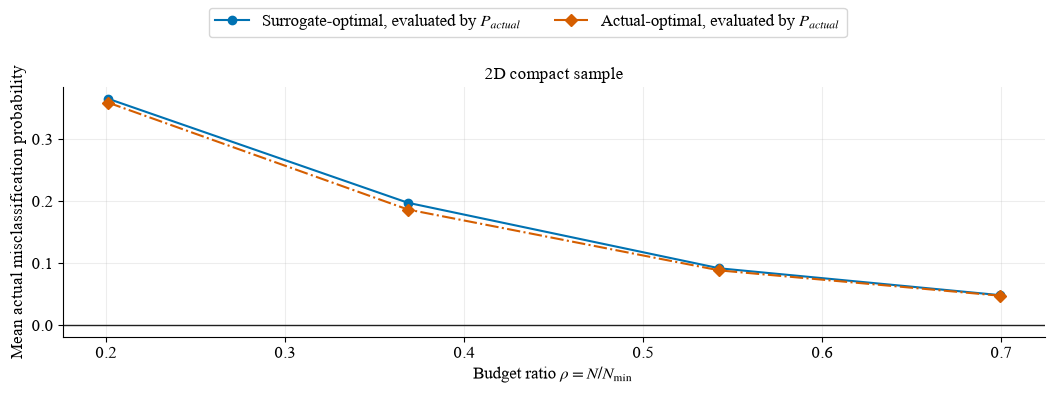

Finished compact_benchmark_2d


In [3]:
def markdown_table(rows, columns, formats):
    header = "| " + " | ".join(label for label, _ in columns) + " |"
    separator = "|" + "|".join("---:" if key in formats else "---" for _, key in columns) + "|"
    body = []
    for row in rows:
        values = []
        for _, key in columns:
            formatter = formats.get(key)
            values.append(formatter(row[key]) if formatter else str(row[key]))
        body.append("| " + " | ".join(values) + " |")
    return "\n".join([header, separator, *body])


def display_dataset_results(dataset, records):
    current_records = {dataset: records}
    summary_rows = actual_optimal_analysis.summarize_actual_optimal_gaps(current_records)
    family_rows = actual_optimal_analysis.gap_rows_by_field_family(current_records)
    budget_rows = actual_optimal_analysis.gap_rows_by_budget(current_records)
    dimension = summary_rows[0]["dimension"]

    display(Markdown(f"## {dimension} Compact Sample"))
    display(Markdown("### Overall Actual-Optimality Gap"))
    display(Markdown(markdown_table(
        summary_rows,
        (
            ("Dataset", "dataset"),
            ("Dimension", "dimension"),
            ("Runs", "runs"),
            ("Mean P_actual(surrogate-optimal)", "mean_surrogate_optimal_actual_error"),
            ("Mean P_actual(actual-optimal)", "mean_actual_optimal_actual_error"),
            ("Mean gap", "mean_actual_optimality_gap"),
            ("Max gap", "max_actual_optimality_gap"),
            ("Mean search seconds", "mean_actual_optimal_seconds"),
            ("Allocation match", "allocation_match_rate"),
            ("Mean allocation L1", "mean_allocation_l1_distance"),
        ),
        {
            "runs": lambda value: f"{int(value)}",
            "mean_surrogate_optimal_actual_error": lambda value: f"{value:.6f}",
            "mean_actual_optimal_actual_error": lambda value: f"{value:.6f}",
            "mean_actual_optimality_gap": lambda value: f"{value:.6f}",
            "max_actual_optimality_gap": lambda value: f"{value:.6f}",
            "mean_actual_optimal_seconds": lambda value: f"{value:.3f}",
            "allocation_match_rate": lambda value: f"{100.0 * value:.1f}%",
            "mean_allocation_l1_distance": lambda value: f"{value:.2f}",
        },
    )))

    display(Markdown("### Actual-Optimality Gap by Field Family"))
    display(Markdown(markdown_table(
        family_rows,
        (
            ("Dataset", "dataset"),
            ("Dimension", "dimension"),
            ("Field family", "field_family"),
            ("Runs", "runs"),
            ("Mean P_actual(surrogate-optimal)", "mean_surrogate_optimal_actual_error"),
            ("Mean P_actual(actual-optimal)", "mean_actual_optimal_actual_error"),
            ("Mean gap", "mean_actual_optimality_gap"),
            ("Max gap", "max_actual_optimality_gap"),
            ("Mean search seconds", "mean_actual_optimal_seconds"),
            ("Allocation match", "allocation_match_rate"),
            ("Mean allocation L1", "mean_allocation_l1_distance"),
        ),
        {
            "runs": lambda value: f"{int(value)}",
            "mean_surrogate_optimal_actual_error": lambda value: f"{value:.6f}",
            "mean_actual_optimal_actual_error": lambda value: f"{value:.6f}",
            "mean_actual_optimality_gap": lambda value: f"{value:.6f}",
            "max_actual_optimality_gap": lambda value: f"{value:.6f}",
            "mean_actual_optimal_seconds": lambda value: f"{value:.3f}",
            "allocation_match_rate": lambda value: f"{100.0 * value:.1f}%",
            "mean_allocation_l1_distance": lambda value: f"{value:.2f}",
        },
    )))

    display(Markdown("### Actual-Optimality Gap by Budget"))
    display(Markdown(markdown_table(
        budget_rows,
        (
            ("Dataset", "dataset"),
            ("Dimension", "dimension"),
            ("Budget level", "budget_level"),
            ("Budget ratio", "budget_ratio"),
            ("Runs", "runs"),
            ("P_actual(surrogate-optimal)", "surrogate_optimal_actual_error"),
            ("P_actual(actual-optimal)", "actual_optimal_actual_error"),
            ("Gap", "actual_optimality_gap"),
            ("Allocation match", "allocation_match_rate"),
            ("Mean allocation L1", "mean_allocation_l1_distance"),
        ),
        {
            "budget_level": lambda value: f"{int(value)}",
            "budget_ratio": lambda value: f"{value:.3f}",
            "runs": lambda value: f"{int(value)}",
            "surrogate_optimal_actual_error": lambda value: f"{value:.6f}",
            "actual_optimal_actual_error": lambda value: f"{value:.6f}",
            "actual_optimality_gap": lambda value: f"{value:.6f}",
            "allocation_match_rate": lambda value: f"{100.0 * value:.1f}%",
            "mean_allocation_l1_distance": lambda value: f"{value:.2f}",
        },
    )))

    figure = actual_optimal_analysis.make_actual_optimal_gap_plot(
        current_records,
        results_root=RESULTS_ROOT,
        sample_scope=SAMPLE_SCOPE,
        figure_stem=f"actual_optimality_gap_{dimension.lower()}",
        save=SAVE_FIGURES,
    )
    display(figure)
    plt.close(figure)


records_by_dataset = {}
for dataset in DATASETS:
    print(f"Starting {dataset}", flush=True)
    if RUN_ACTUAL_OPTIMAL_SEARCH:
        current = actual_optimal_analysis.run_actual_optimal_validation(
            (dataset,),
            comparison_results_root=COMPARISON_RESULTS_ROOT,
            results_root=RESULTS_ROOT,
            input_root=INPUT_ROOT,
            comparison_run_scope=COMPARISON_RUN_SCOPE,
            replicates_per_cell=REPLICATES_PER_CELL,
            k_values=K_VALUES,
            m_values=M_VALUES,
            sample_scope=SAMPLE_SCOPE,
            progress_every=1,
        )
        records = current[dataset]
    else:
        records = actual_optimal_analysis.load_actual_optimal_results(
            dataset,
            results_root=RESULTS_ROOT,
            sample_scope=SAMPLE_SCOPE,
        )
    records_by_dataset[dataset] = records
    print(dataset, "records:", len(records), flush=True)
    display_dataset_results(dataset, records)
    print(f"Finished {dataset}", flush=True)


## Saved Files

When `RUN_ACTUAL_OPTIMAL_SEARCH = True`, detailed records are saved under the active `SAMPLE_SCOPE`:

```text
results/actual_optimal/compact_<1d|2d>_<SAMPLE_SCOPE>/tables/
- results.json
- summary.csv
```

When `SAVE_FIGURES = True`, per-dimension plots are saved under the same scope:

```text
results/actual_optimal/summary_<SAMPLE_SCOPE>/figures/
- actual_optimality_gap_1d.png
- actual_optimality_gap_1d.pdf
- actual_optimality_gap_2d.png
- actual_optimality_gap_2d.pdf
```
